In [2]:
import cv2
from skimage.util import random_noise
import numpy as np
from matplotlib import pyplot as plt


b: 23 g: 23 r: 39


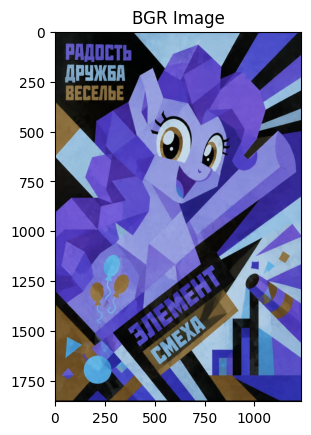

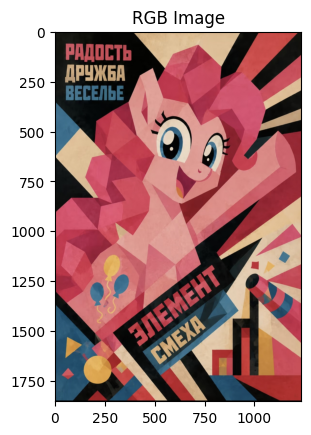

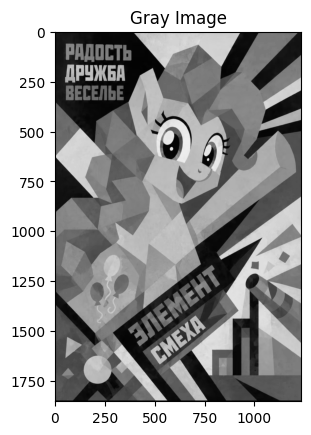

In [19]:
#读取原始图像
img = cv2.imread('p1.jpg')
# 获取(100,100)位置B G R像素值
(b, g, r) = img[100, 100]
print("b:", b, "g:", g, "r:", r)

# 原始BGR图像直接显示（颜色会错乱）
plt.imshow(img)
plt.title('BGR Image')
plt.savefig('output_images/bgr_image.jpg', dpi=300)
plt.show()

# BGR转为RGB，修正颜色
rgb_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(rgb_img)
plt.title('RGB Image')
plt.savefig('output_images/rgb_image.jpg', dpi=300)
plt.show()

# 转换灰度图
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
plt.imshow(gray_img, cmap='gray')
plt.title('Gray Image')
plt.savefig('output_images/gray_image.jpg', dpi=300)
plt.show()


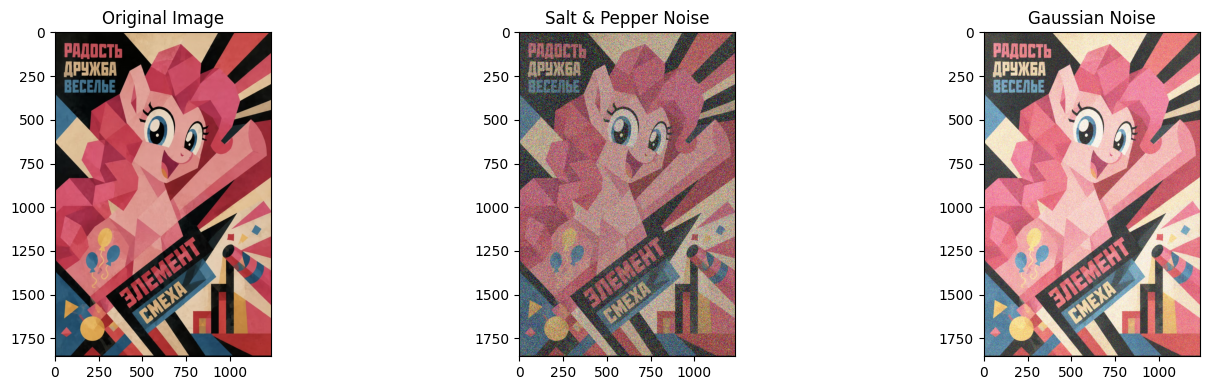

In [14]:
# 添加椒盐噪声 40%像素受噪声污染
sp_noise_img = random_noise(rgb_img, mode='s&p', amount=0.4)
# 添加高斯噪声
gus_noise_img = random_noise(rgb_img, mode='gaussian', mean=0.2, var=0.03)
# 噪声阶段截断
sp_noise_img = np.clip(sp_noise_img,0,1)
gus_noise_img = np.clip(gus_noise_img,0,1)

plt.figure(figsize=(15,4))
plt.subplot(1, 3, 1)
plt.imshow(rgb_img)
plt.title('Original Image')

plt.subplot(1, 3, 2)
plt.imshow(sp_noise_img)
plt.title('Salt & Pepper Noise')

plt.subplot(1, 3, 3)
plt.imshow(gus_noise_img)
plt.title('Gaussian Noise')

plt.tight_layout()
plt.savefig('output_images/noise_comparison.jpg', dpi=300)
plt.show()


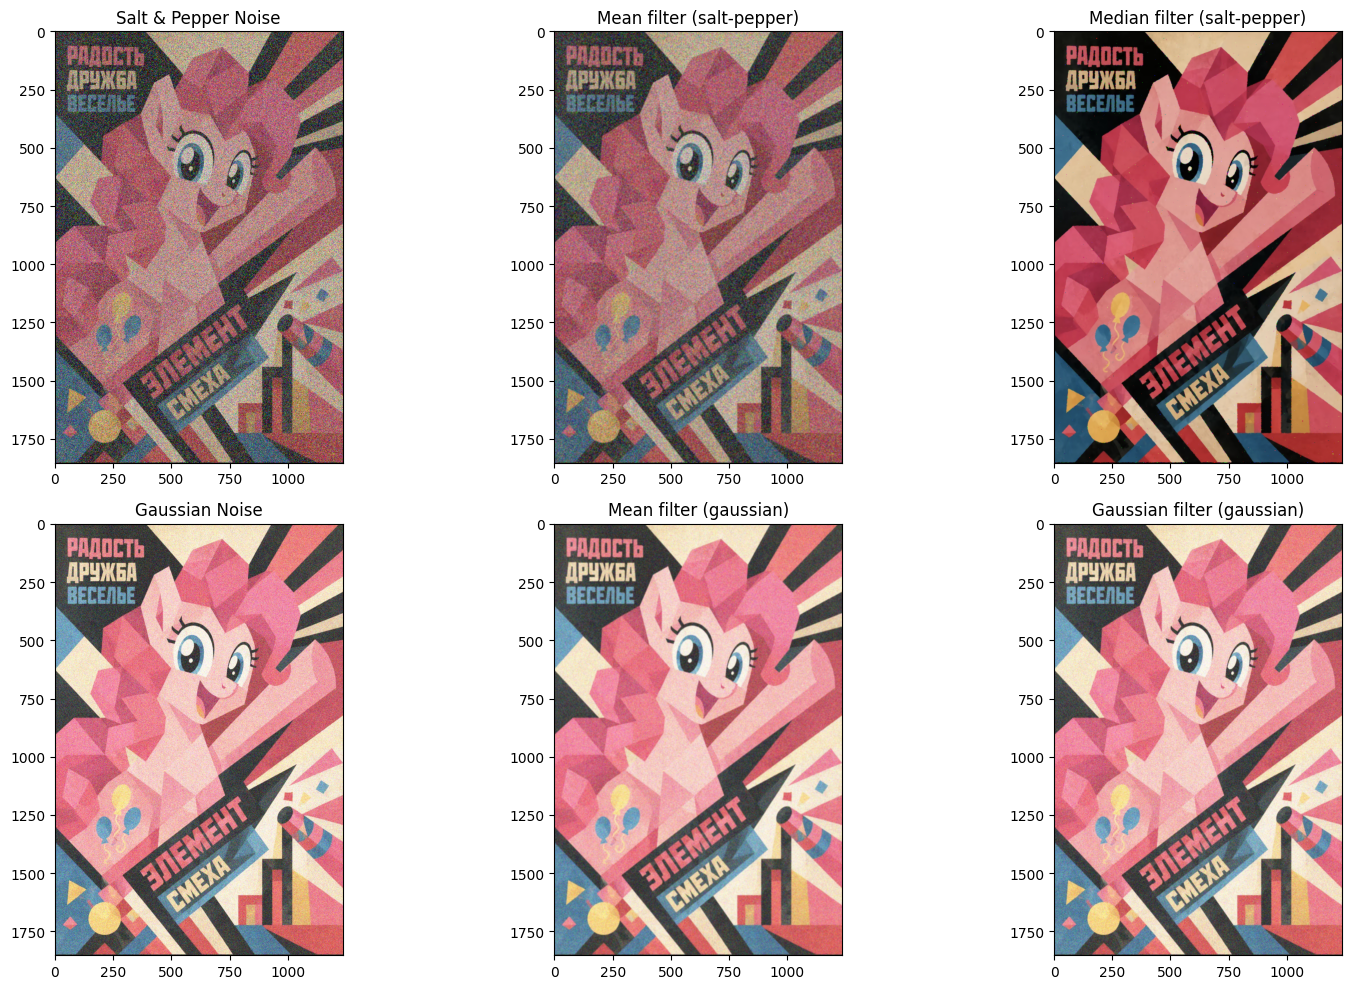

In [17]:
# 全部先转uint8，所有cv滤波都用uint8，避免float运算溢出
sp_noise_uint8 = np.clip(sp_noise_img*255,0,255).astype(np.uint8)
gus_noise_uint8 = np.clip(gus_noise_img*255,0,255).astype(np.uint8)

# 均值滤波
mean_sp = cv2.blur(sp_noise_uint8, (5,5))
mean_gus = cv2.blur(gus_noise_uint8, (5,5))
# 中值滤波
median_sp = cv2.medianBlur(sp_noise_uint8, 5)
median_gus = cv2.medianBlur(gus_noise_uint8, 5)
# 高斯滤波
gauss_sp = cv2.GaussianBlur(sp_noise_uint8, (5,5), 0)
gauss_gus = cv2.GaussianBlur(gus_noise_uint8, (5,5), 0)

plt.figure(figsize=(16,10))
# 第一行：椒盐噪声经过三种滤波
plt.subplot(2,3,1)
plt.imshow(sp_noise_uint8)
plt.title('Salt & Pepper Noise')

plt.subplot(2,3,2)
plt.imshow(mean_sp)
plt.title('Mean filter (salt‑pepper)')

plt.subplot(2,3,3)
plt.imshow(median_sp)
plt.title('Median filter (salt‑pepper)')

# 第二行：高斯噪声经过三种滤波
plt.subplot(2,3,4)
plt.imshow(gus_noise_uint8)
plt.title('Gaussian Noise')

plt.subplot(2,3,5)
plt.imshow(mean_gus)
plt.title('Mean filter (gaussian)')

plt.subplot(2,3,6)
plt.imshow(gauss_gus)
plt.title('Gaussian filter (gaussian)')

plt.tight_layout()
plt.savefig('result/filter_result.jpg', dpi=300)
plt.show()


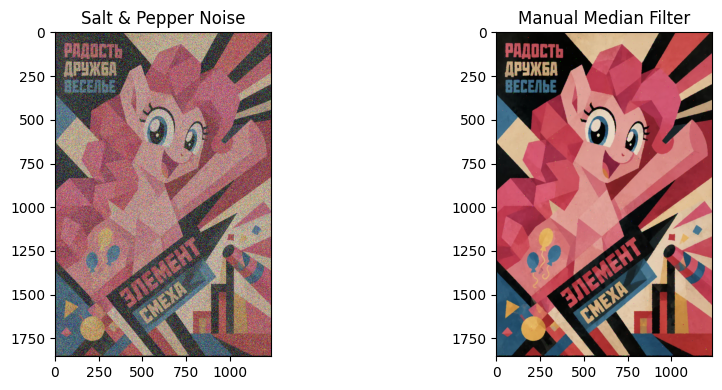

In [18]:
def my_median_filter(image, kernel_size=5):
    h, w, c = image.shape
    pad = kernel_size // 2
    # edge模式边缘填充
    pad_img = np.pad(image, ((pad,pad),(pad,pad),(0,0)), mode='edge')
    out = np.zeros_like(image)
    
    for i in range(h):
        for j in range(w):
            for ch in range(c):
                window = pad_img[i:i+kernel_size, j:j+kernel_size, ch]
                out[i,j,ch] = np.median(window)
    return out

# 使用已经转好uint8的椒盐噪声图片
my_median_out = my_median_filter(sp_noise_uint8, kernel_size=5)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(sp_noise_uint8)
plt.title('Salt & Pepper Noise')

plt.subplot(1,2,2)
plt.imshow(my_median_out)
plt.title('Manual Median Filter')

plt.tight_layout()
plt.savefig('result/manual_median.jpg', dpi=300)
plt.show()
